# Индивидуальная КТ/FEM-проверка трёх участников Scorpion — ПРЕДВАРИТЕЛЬНЫЙ ОТЧЁТ

**ПРЕДВАРИТЕЛЬНЫЙ ОТЧЁТ: дополнительные прямые расчёты не завершены.** Исследовательский этап разработки методики, 26 октября 2026 года.

Цель — проверить, что объясняют индивидуальные прямые модели базового импеданса,
какие тканевые параметры различимы локально и как условные тканевые и объёмные
сценарии изменяют электрический ответ. Представлены три самостоятельные модели;
данные между участниками не переносятся. Георгий, Ник и Ярослав — принятые
проектом псевдонимы; ФИО и пространственные исходники не раскрываются.

Проверки численного решения и интегрирования пройдены в указанном ниже объёме.
Совпадение с экспериментальными уровнями и практическая идентифицируемость
параметров этим не установлены. Шесть пробных переносов электродов отклонены
до проверки новых площадок. Готовность расчётов замещения сердца: 13 из 24;
новых материальных ветвей: 1 из 6.
Все таблицы раскрываются по действию читателя.

1. [Входы, прямая модель и контроль](#inputs)
2. [Базовые уровни и два источника](#baseline)
3. [Парное дыхательное различие](#breath)
4. [Различимость сопротивлений](#svd)
5. [Четыре тканевых возмущения](#basis)
6. [Объём эквивалентной сферы](#sphere)
7. [Авторский диапазон сопротивлений](#range)
8. [Вывод и происхождение](#conclusion)

In [1]:
from pathlib import Path
import sys,json
here=Path.cwd()
folder=here if (here/'build_scorpion_fem_smart_report.py').is_file() else next(p/'Colab Notebooks/scorpion_v2' for p in [here,*here.parents] if (p/'Colab Notebooks/scorpion_v2/build_scorpion_fem_smart_report.py').is_file())
sys.path.insert(0,str(folder))
import build_scorpion_fem_smart_report as F
from IPython.display import HTML,display
get_ipython().run_line_magic('matplotlib','inline')
S=json.loads((folder/'_assets/fem_smart_20261026.summary.json').read_text(encoding='utf-8'))
F.assert_safe(S)

<a id="inputs"></a>
## 1. Индивидуальные входы, прямая модель и границы проверок

**Подтверждённые входы.** Использованы собственные КТ и подготовленные сетки трёх
участников. КТ получены на глубоком вдохе с задержкой дыхания. Фон, лёгкое,
кость, всё сердце и жир образуют пять материалов. Индивидуальная геометрия
и собственные маски TotalSegmentator v2.18.0 служат входами прямого расчёта.
Паспорта связывают исходную КТ и каждую маску SHA; для сетки используются
отдельные маски вычислительной области. Нативные анатомические STL и сетки
вычислительной области сохраняют разные назначения. Анатомический просмотр
автоматических масок остаётся отдельной проверкой. Качество электрического прогноза
не следует из одного успешного геометрического контроля.

**Модельные допущения.** Расчёт выполнен при 100 кГц в MATLAB/EIDORS с конечными
контактами в полной электродной модели (CEM), методом конечных элементов (FEM):
номинальные диски диаметром 5 мм, фактические дискретные площадки
и группировка физически присутствующих электродов. Контактный импеданс задан
сценарием. Кость фиксирована. Сердце рассматривается как единая эффективная
область, без разделения крови и миокарда. Система решается в СИ; передаточный
импеданс — отношение напряжения к току, в омах.

В реализации используются вещественные удельные сопротивления и проводимости
σ=1/ρ. Комплексные проводимости тканей не используются. Для всех контактов
трёх участников задано zcontact=0,01 Ом·м²; это рабочий CEM-сценарий,
контактный импеданс независимо не измерен. Числа и основание назначения
связаны с сохранённым контактным паспортом.

Цилиндрические руки имеют принятый обхват 370 мм и радиус 370/(2π)≈58,89 мм.
Для Георгия это указание автора от 08.10.2026, для Ника — от 22.10.2026;
для Ярослава это приближённое назначение. Эти разные статусы не объединяются
в утверждение о трёх одинаково измеренных обхватах.

Для оценки вычислительной согласованности сопоставляются невязка линейной
системы и взаимность с допусками 10⁻⁷, производные с центральной разностью
по lnρ с шагом 0,001 и относительным допуском 10⁻⁴. Правила q1024/q4096
относятся к интегрированию материалов внутри одной сетки. Их различие
проверяется для базовых уровней по критерию 0,02 Ом + 0,001·|Zq4096|.
Таблица 1 показывает фактический охват сохранённых проверок.

**Параметры контрольного расчёта.** Георгий / Ник / Ярослав: фон 2,763585998; лёгкое на вдохе 9,315252925, в условном сценарии выдоха 3,681694081; кость 48,097673526; целое сердце 4,648809058; жир 23,040605218 Ом·м. Источник — частотные значения Gabriel при 100 кГц в [числовом реестре тканей](../../MATLAB_TRKG4_real_subjects/configs/tissue_literature_v2.json), его SHA связан с каждым расчётом. В новой ветви с однородной кровью жир и кость сохраняют именно эти значения. Индивидуальная подгонка не выполнялась. Число знаков отражает сохранённый числовой профиль и не задаёт метрологическую точность. Одинаковые опорные свойства не означают одинаковых индивидуальных геометрий или чувствительностей.

In [2]:
display(HTML(F.qc_table(S)))

Участник,Систем,Макс. невязка,"Взаимность, Ом",FD: макс. относительная ошибка,q1024/q4096
Георгий,28,"4,23793e-14","8,52651e-14","7,89084e-08",Пройден
Ник,16,"1,66579e-14","8,52651e-14","8,05192e-08",Пройден
Ярослав,16,"1,79207e-14","5,68434e-14","1,17232e-07",Пройден


FD-проверка выполнена для монтажа 140 мм с ТТРКГ 2×2 на вдохе; остальные
монтажи и условный выдох не получили отдельной FD-проверки. Сеточная сходимость,
ошибка сегментации и экспериментальная точность остаются самостоятельными
вопросами. При переносе на пять миллиметров сначала проверялась проекция новых
центров на прежнюю поверхность (таблица 2).

In [3]:
display(HTML(F.placement_table(S)))

Участник,"Сдвиг Y, мм","Проекция: минимум, мм","Проекция: максимум, мм",Статус
Георгий,-5,"1,1151","2,01318",ct_fem:projection
Георгий,5,"0,654744","1,86865",ct_fem:projection
Ник,-5,"1,67938","2,3153",ct_fem:projection
Ник,5,"1,53752","2,65117",ct_fem:projection
Ярослав,-5,"1,19296","2,50283",ct_fem:projection
Ярослав,5,"1,36006","2,59011",ct_fem:projection


**Отрицательный результат проверки размещения.** Все шесть сценариев
остановились на прежнем допуске проекции 1 мм. Задавалось смещение исходного
центра на [0,±5,0] мм в LPS перед проекцией; геодезическая длина не фиксировалась.
Допуски не расширялись. Этот отказ относится к геометрической операции по
заданной оси: новые footprint и электрическая устойчивость к размещению
остались непроверенными. Необходимость сгущения сетки данным отказом не установлена.
Сценарные ±5 мм не являются доверительной погрешностью наклейки.

<a id="baseline"></a>
## 2. Базовые уровни и неизвестная фаза двух источников

**Экспериментальные наблюдения.** Сопоставляются сохранённые уровни на
ретроспективно выделенных интервалах дыхательного протокола. Разметка остаётся
кандидатной; повторения одного монтажа сведены медианой, число повторений
сохраняется в агрегате. Разные размеры регистрировались последовательно.
Время, контакт и состояние участника могут различаться между записями.

**Сценарий прямой модели.** Основной прогноз использует собственный источник
отведения — own_drive. Фактическая относительная фаза двух источников и
оператор демодуляции прибора не подтверждены. Поэтому невязка этого прогноза
не устанавливает единственную причину расхождения с измерением.
Проверим отдельно размерную зависимость и варианты ТТРКГ.

Сравнение на вдохе сохраняет различия размеров и группировки электродов (рисунок 1).

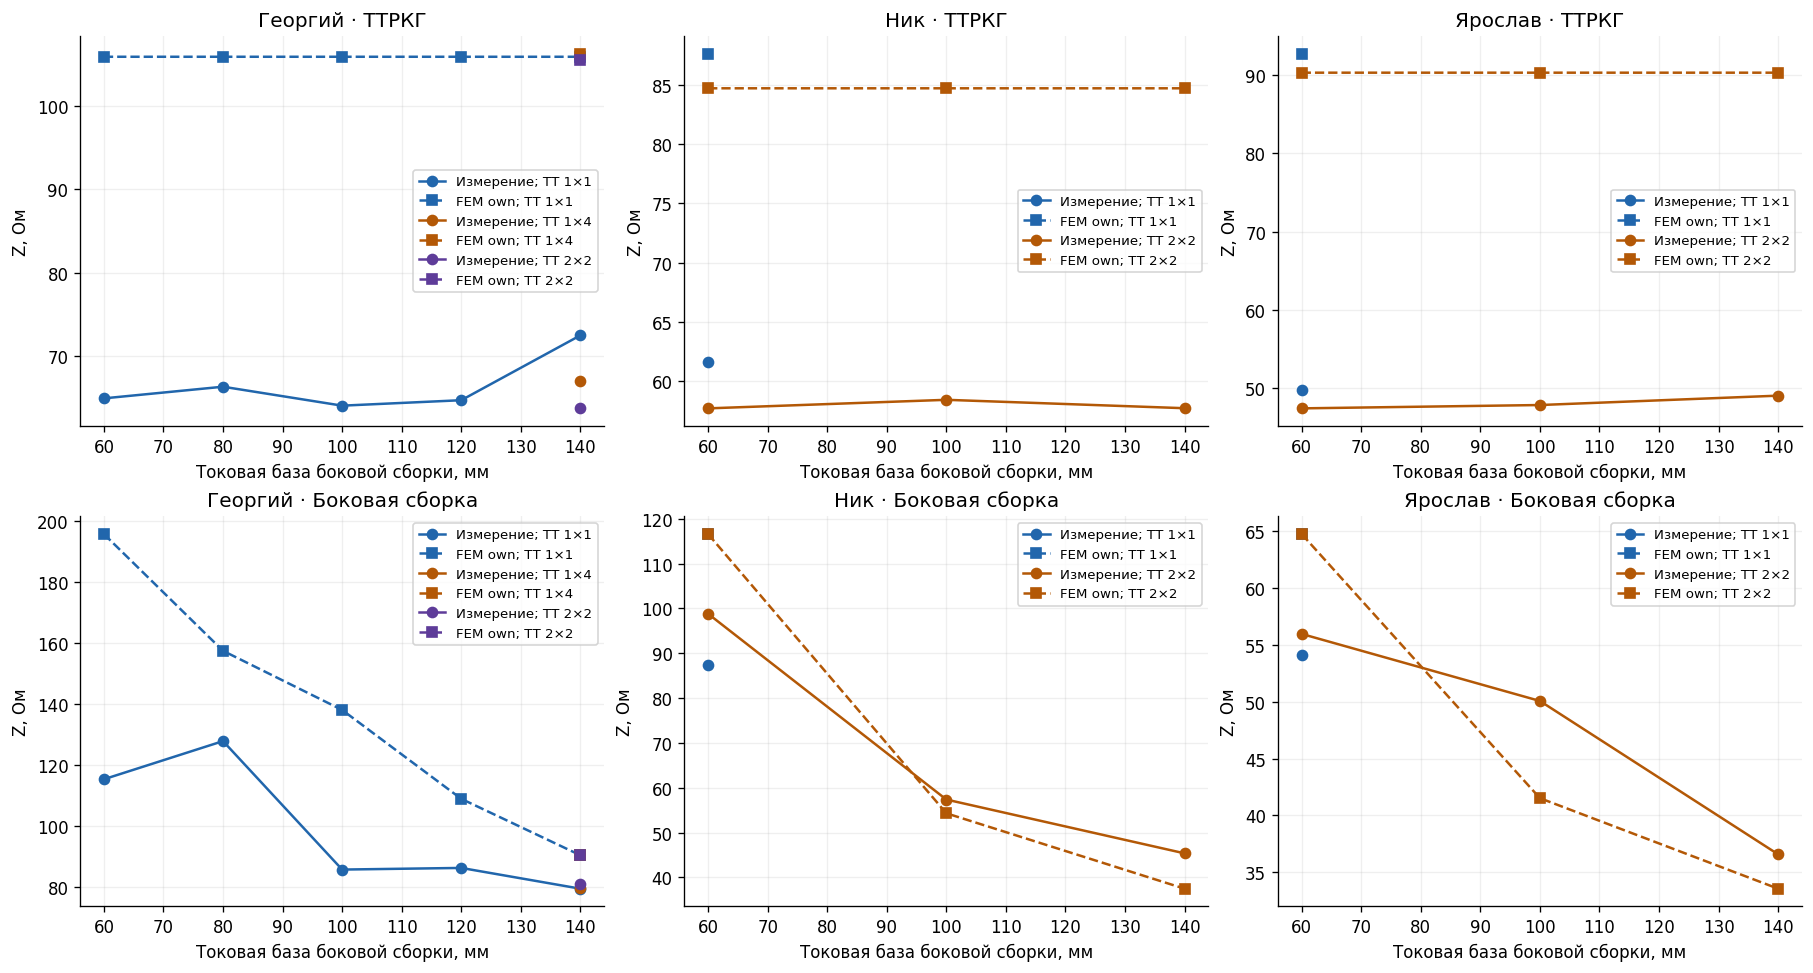

In [4]:
F.show_figure(F.fig_baseline(S))

**Рисунок 1. Измеренные медианные уровни и FEM-прогноз own_drive на вдохе. Столбцы — участники; верхний ряд — ТТРКГ, нижний — боковая сборка. Цвет различает вариант ТТРКГ, сплошные линии с кружками — наблюдение, пунктир с квадратами — модель. База указана по боковой сборке.**

На рисунке 1 представлены условные прямые прогнозы без подгонки сопротивлений или усиления. Невязки первичного монтажа 140 мм/2×2: Георгий: ТТРКГ +41.707 Ом, Боковая сборка +9.438 Ом; Ник: ТТРКГ +26.967 Ом, Боковая сборка -7.887 Ом; Ярослав: ТТРКГ +41.397 Ом, Боковая сборка -3.024 Ом. Эти различия относятся к выбранным материалам, контактам и own_drive; совпадение формы размерной зависимости не заменяет проверки абсолютных уровней.

Сохранённые перекрёстные элементы позволяют отдельно рассмотреть два
источника одинаковой амплитуды без нового FEM. Для каждого отведения a —
собственный ответ, b — ответ от соседнего источника. При φ=0 знаковый ответ
равен a+b, при φ=π — a−b; возможный модуль при неизвестной фазе лежит между
||a|−|b|| и |a|+|b|. Это линейная модель двух источников с заданными токами (1).
Она не определяет реальную демодуляцию. Сопоставление в таблице 3 относится
к первичному монтажу 140 мм и ТТРКГ 2×2 на вдохе.

In [5]:
display(HTML(F.phases_table(S)))

Участник,Отведение,"Измерение, Ом","own, Ом","cross, Ом","φ=0, Ом","φ=π, Ом","Минимум модуля, Ом","Максимум модуля, Ом"
Георгий,ТТРКГ,"63,73","105,437","-22,5293","82,9076","127,966","82,9076","127,966"
Георгий,Боковая сборка,"80,9534","90,3919","-9,37802","81,0139","99,7699","81,0139","99,7699"
Ник,ТТРКГ,"57,7355","84,7024","-15,9266","68,7759","100,629","68,7759","100,629"
Ник,Боковая сборка,"45,3529","37,4656","-7,12723","30,3383","44,5928","30,3383","44,5928"
Ярослав,ТТРКГ,"48,9601","90,3573","-15,2623","75,0949","105,62","75,0949","105,62"
Ярослав,Боковая сборка,"36,5591","33,5355","-7,19631","26,3392","40,7318","26,3392","40,7318"


В таблице 3 число участников, у которых положительный измеренный уровень ТТРКГ ниже нижней модельной границы модуля: 3 из 3. В этих случаях изменение одной фазы не устраняет расхождение в пределах рассматриваемой модели. Вывод условен при заданных материалах и равных токах; режим прибора им не установлен.

<a id="breath"></a>
## 3. Парное различие между вдохом и выдохом

Дыхательный контраст определяется как ΔZ=Zвыдох−Zвдох (2). Каждая разность
формируется внутри одной записи и отведения до объединения повторений.
Это сохраняет парность сравнения и отделяет контраст от абсолютного уровня.
В FEM меняются сопротивления; исходная КТ глубокого вдоха остаётся неизменной.
Следовательно, модельный выдох является условным материальным сценарием.

Проверим величину и знак парного контраста для каждого монтажа (рисунок 2).

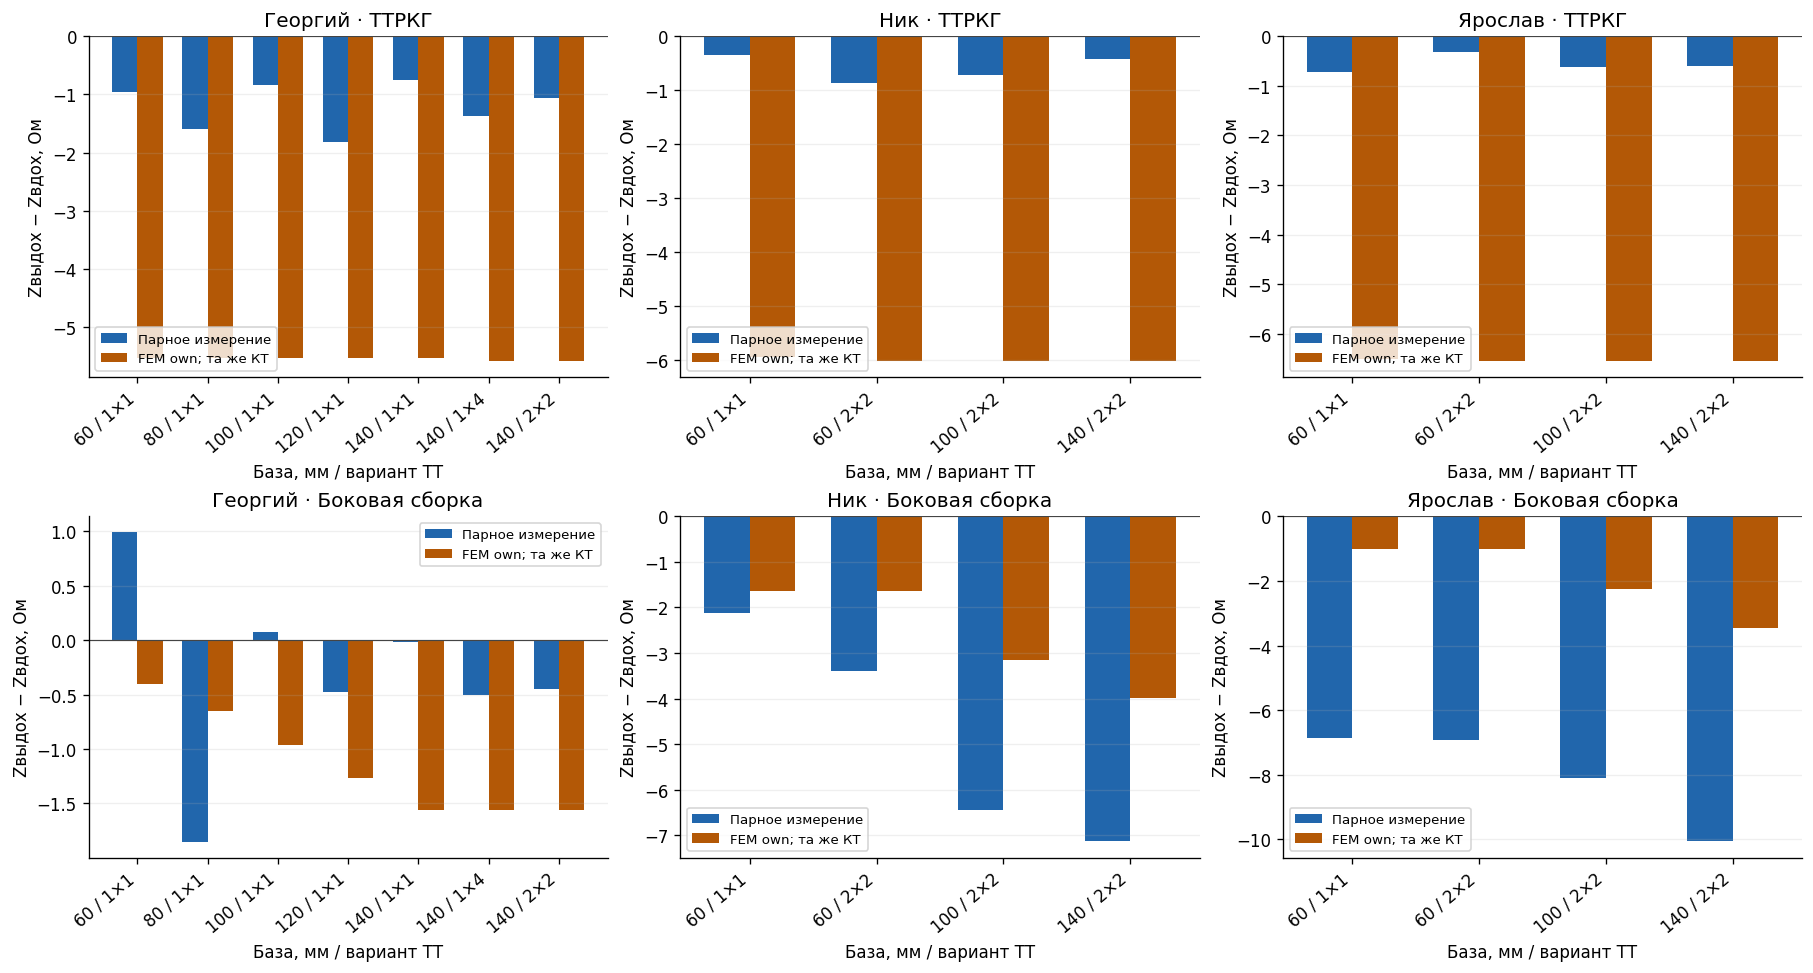

In [6]:
F.show_figure(F.fig_breath(S))

**Рисунок 2. Парные дыхательные разности: наблюдение и условный FEM own_drive. Синий столбец — медиана парных разностей, оранжевый — модель. Категории обозначают базу боковой сборки в миллиметрах и вариант ТТРКГ.**

По рисунку 2: Георгий: первичный ТТРКГ — наблюдение -1.068 Ом, модель -5.578 Ом; число боковых монтажей с различным знаком наблюдения и модели — 2; Ник: первичный ТТРКГ — наблюдение -0.4164 Ом, модель -6.014 Ом; число боковых монтажей с различным знаком наблюдения и модели — 0; Ярослав: первичный ТТРКГ — наблюдение -0.602 Ом, модель -6.538 Ом; число боковых монтажей с различным знаком наблюдения и модели — 0. Геометрическое изменение грудной клетки здесь не рассчитывалось. Ретроспективная разметка, последовательность монтажей и отсутствие оценки межсессионной неопределённости ограничивают количественную интерпретацию расхождения.

<a id="svd"></a>
## 4. Локальная различимость четырёх сопротивлений

Сохранённый adjoint Jacobian задаёт Jlog=dZ/dlnρ. Его столбцы соответствуют
фону, лёгкому, всему сердцу и жиру; кость фиксирована. Ненормированная
производная равна dZ/dρj=Jlog,j/ρj (3), с единицами 1/м.
Для сравнения масштабов используется явно безразмерная матрица
Eij=Jlog,ij/Zi (4). Знаки Z и производных сохранены; эта нормировка не задаёт
шумовую дисперсию. SVD разлагает E на ортогональные направления, а сингулярные
числа характеризуют величину ответа на возмущения lnρ в этих направлениях.

Боковые строки, ТТРКГ и их совместный набор рассматриваются раздельно.
Совместный набор объединяет все сохранённые монтажи одного участника и состояния.
Одна пара ТТРКГ/боковой сборки даёт два наблюдения для четырёх rho.
Формальный ранг при машинном пороге не доказывает практической определимости.

Сопоставим сингулярный спектр с наблюдаемым изменением матрицы при смене правила интегрирования (рисунок 3).

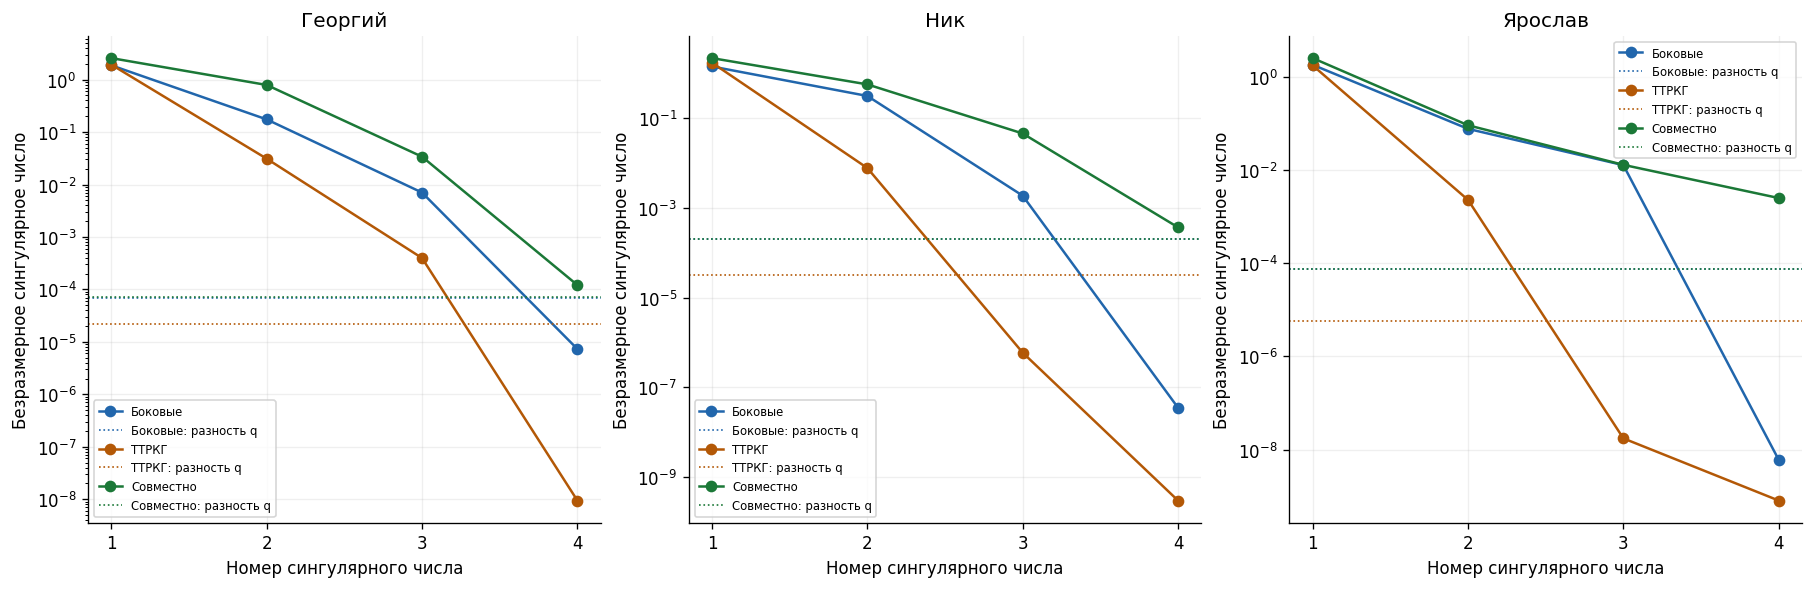

In [7]:
F.show_figure(F.fig_svd(S))

**Рисунок 3. Сингулярные числа безразмерной E на вдохе, логарифмическая шкала. Сплошные линии — боковые, ТТРКГ и совместный набор; цветные пунктирные уровни — спектральная норма Eq4096−Eq1024 для соответствующего набора.**

Обусловленность на рисунке 3: Георгий: боковые 2.56e+05, ТТРКГ 2.04e+08, совместно 2.12e+04; Ник: боковые 3.93e+07, ТТРКГ 5.57e+09, совместно 5.84e+03; Ярослав: боковые 3.04e+08, ТТРКГ 2.22e+09, совместно 1.01e+03. Слабейшее совместное направление у всех трёх участников преимущественно связано с эффективным сопротивлением всего сердца. Разность интеграционных правил является наблюдаемым численным контролем, её нельзя считать строгой границей ошибки. Шум и неопределённость положения не оценены; раздельная практическая оценка четырёх rho не установлена.

<a id="basis"></a>
## 5. Четыре знаковых тканевых возмущения

Для первичного монтажа задаются четыре независимых базисных сценария:
δlnρj=0,01 для одного материала, остальные возмущения равны нулю.
Линейный прогноз δZ≈Jlog·δlnρ (5) вычисляется по сохранённым производным.
Это заданные малые возмущения свойств тканей; их амплитуда не измерена
как пульсовое изменение участника. Кость и геометрия остаются постоянными.

Сравним знаки и масштабы ответа двух отведений на одинаковое логарифмическое возмущение (рисунок 4).

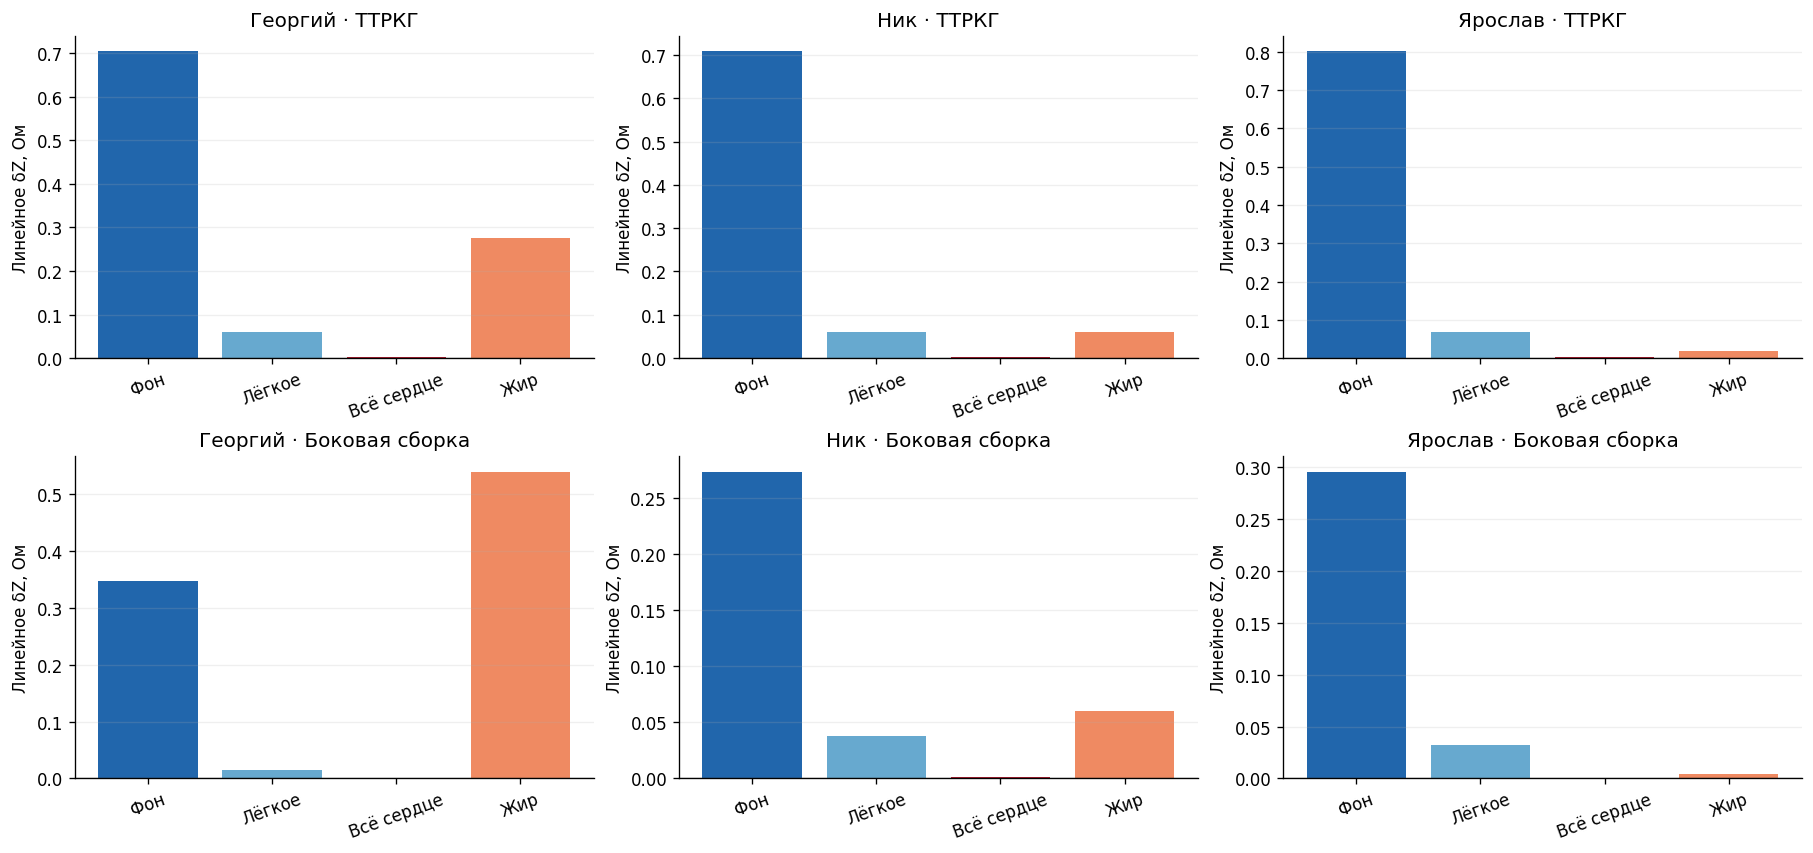

In [8]:
F.show_figure(F.fig_basis(S))

**Рисунок 4. Линейное δZ для четырёх базисных сценариев δlnρ=0,01 на вдохе. Монтаж 140 мм/ТТРКГ 2×2, q4096. Каждый столбец соответствует самостоятельному возмущению; одновременно они не суммируются.**

На рисунке 4 ответ ТТРКГ на изолированное δlnρ целого сердца=0,01 составляет: Георгий +0.00371678 Ом; Ник +0.0032691 Ом; Ярослав +0.00360361 Ом. Знак передаточной чувствительности определяется полями токовой и измерительной пар. Полученные столбцы не являются измеренными источниками пульса; ЭКГ-синхронность не разделяет их автоматически. Точность линейного приближения для выбранной конечной амплитуды здесь отдельно не проверена.

<a id="sphere"></a>
## 6. Эквивалентная сфера и объёмная чувствительность

Сфера строится по объёму маски всего сердца конкретного участника.
Рассматриваются целевые объёмы 0,95V₀, V₀ и 1,05V₀ при фиксированном центре.
Исходная область сердца заменяется фоном; внутри сферы материал сердца имеет
приоритет, после выхода сферы восстанавливается фоновый материал.
Это явное назначение материалов на неподвижной КТ, без механического переноса органов.
Контроль с исходной маской целого сердца должен воспроизвести базовый расчёт до
интерпретации изменения формы. Три объёмных состояния задают секущую;
сходимость по шагу объёма и обратная задача этим не проверены.

Рассмотрим только фактически сохранённые прямые ответы объёмных вариантов (рисунок 5).

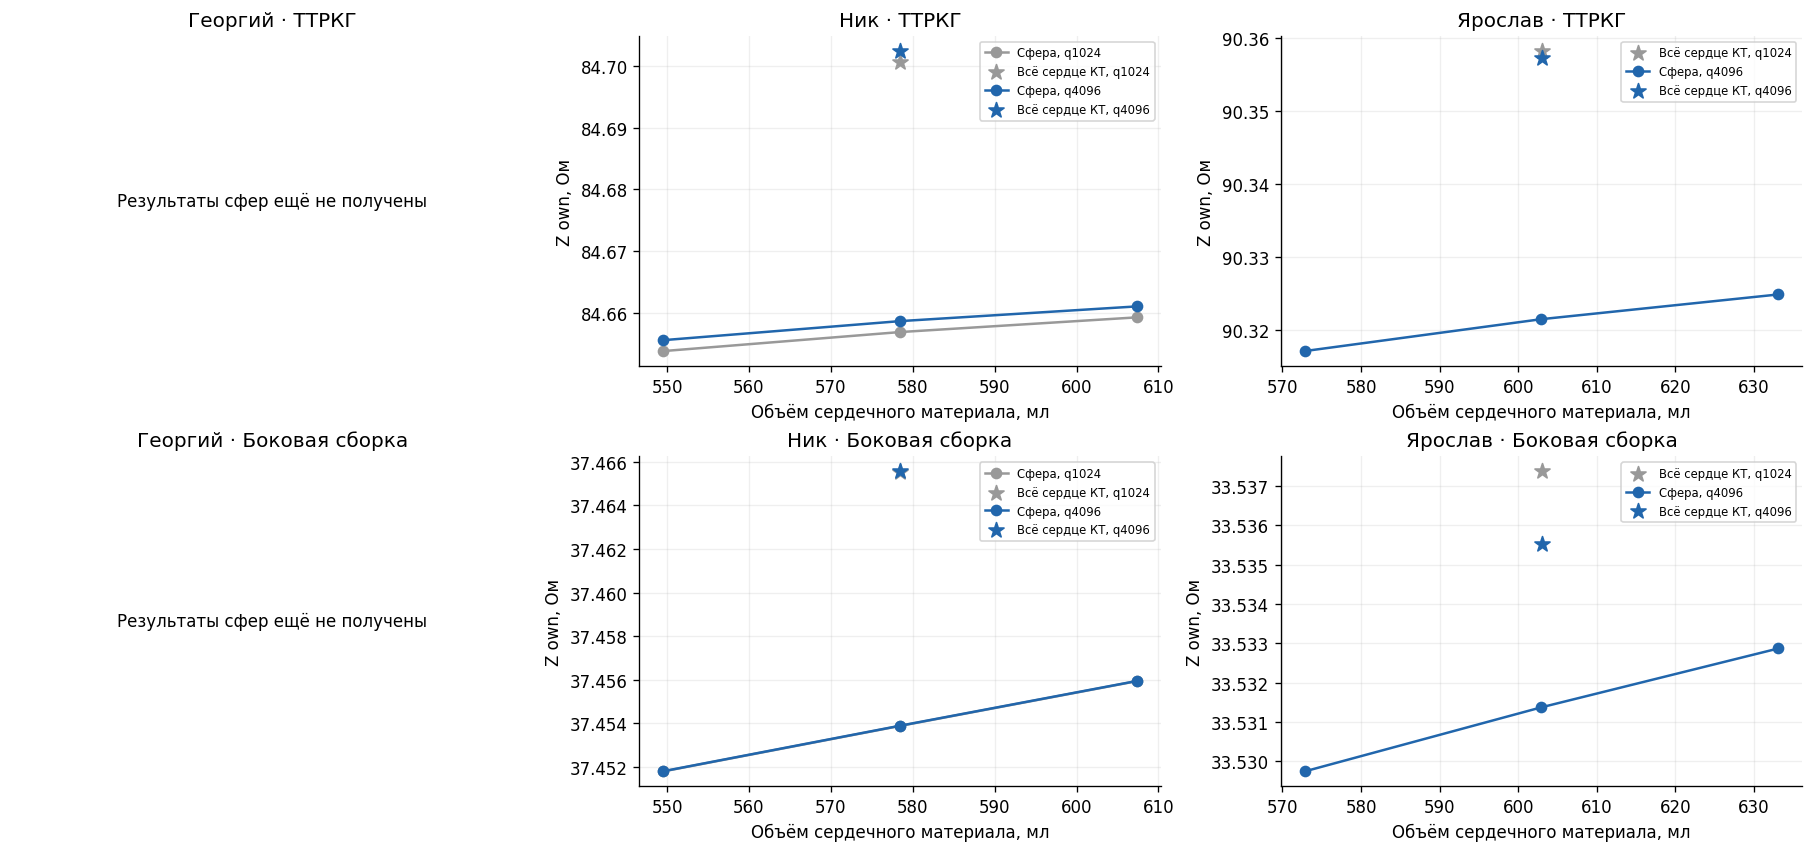

In [9]:
F.show_figure(F.fig_sphere(S))

**Рисунок 5. Импеданс own_drive в зависимости от интегрированного объёма сердечного материала. Кружки и линии — три сферических состояния, звёзды — исходная маска целого сердца; серый — q1024, синий — q4096. Контрольный расчёт при ρцелого сердца≈4,6488 Ом·м.**

Рисунок 5 отделяет эффект изменения формы от эффекта изменения объёма. Контрольный расчёт использует эффективное сопротивление целого сердца около 4,6488 Ом·м. Размах модельных объёмов не является ударным объёмом. Объёмная чувствительность не переводится в УО/ФВ без отдельной проверенной связи с физиологическими камерными объёмами.

**Фактический контроль формы и объёма.** Ник: изменение ТТРКГ при равнообъёмной замене формой сферы -0.0437484 Ом, отклик между 0,95V₀ и 1,05V₀ +0.00546931 Ом, разность q для собственного ТТРКГ сферы V₀ +0.00177139 Ом. Если эффект формы превосходит проверенный объёмный контраст, объём сферы особенно нельзя отождествлять с анатомическим объёмом. Эти два эффекта сопоставлены в омах; пересчёт ошибки формы в миллилитры по секущей не выполняется. Разность интегрирования собственного ТТРКГ отделена от максимума по всем элементам портовой матрицы.

<a id="range"></a>
## 7. Авторский диапазон сопротивлений и отдельный сценарий всего сердца

**Авторское условие новой ветви.** Мягкотканному фону назначается диапазон
2–3 Ом·м, лёгкому — 2–12 Ом·м, всему сердцу — однородное 1,35 Ом·м.
Значение крови используется здесь как заданное свойство всей сердечной области;
смесь крови и миокарда им независимо не определена. Жир и кость фиксированы.
Диапазон мышц присвоен эффективному фону неразмеченных мягких тканей;
самостоятельная анатомическая маска мышц в этой постановке отсутствует.
Сканирование использует фон 2; 2,5; 3 Ом·м и лёгкое 2; 4; 7; 10; 12 Ом·м:
15 точек q4096 и пять контрольных точек q1024. Это сценарная сетка, а не
доверительный диапазон индивидуальных параметров. Отдельные восемь объёмных
результатов новой ветви вычисляются при фоне 2,5, лёгком 7 и сердце 1,35 Ом·м.

Новые прямые результаты принимаются только по собственным завершённым
планам и SHA. Их own_drive, φ=0, φ=π и границы модуля следует сопоставлять
раздельно, без подгонки усиления. До завершения прямых расчётов численные поля
остаются пустыми. Диапазон Z по такой сетке нельзя восстановить из контрольного
расчёта при сопротивлении целого сердца 4,6488 Ом·м
или линейной экстраполяцией. Таблица 4 показывает фактическую готовность.

In [10]:
display(HTML(F.status_table(S)))

Участник,Замещение сердца: готово / 8,Сканирование диапазона,"Сфера при 1,35 Ом·м"
Георгий,0,pending,pending
Ник,8,completed,pending
Ярослав,5,pending,pending


Скриншот расчёта коллеги служит качественным ориентиром изменения ответа
при повышении сопротивления фона и лёгкого. Исходный файл, геометрия и определение
измеряемого Z недоступны. По уточнению автора возможна двуслойная сфера
«миокард + кровь»; текущая первая ветвь по его поручению использует однородную
кровь 1,35 Ом·м. Скриншот не оцифровывается и не служит независимой валидацией.

Для центра новой сетки ρфон=2,5, ρлёгкое=7, ρсердце=1,35 Ом·м заново
используется собственный Jlog этой точки. Таблица 6 раздельно показывает
четыре столбца и редуцированные [фон, лёгкое] при фиксированных сердце, жире
и кости. Одна первичная пара даёт две строки и не определяет четыре rho.
Полный ранг редуцированной матрицы означает лишь локальную условную
определимость при перечисленных фиксированных параметрах; реальные
индивидуальные сопротивления этим не восстановлены. Таблица 5 сохраняет
границы сценарной сетки Z без интерпретации их как доверительных интервалов.
Для отсутствующих результатов числовые строки остаются пустыми.

In [11]:
display(HTML(F.range_tables(S)))

Участник,Монтаж,Отведение,Источник: сценарий,"Z мин., Ом","Z макс., Ом",Точек
Ник,L100_TT2x2,ТТРКГ,own_drive,"56,8018","91,9176",15
Ник,L100_TT2x2,ТТРКГ,φ=0,"50,5448","80,0597",15
Ник,L100_TT2x2,ТТРКГ,φ=π,"63,0587","103,776",15
Ник,L100_TT2x2,ТТРКГ,Модуль при неизвестной φ,"50,5448","103,776",15
Ник,L100_TT2x2,Боковая сборка,own_drive,"40,9278","57,827",15
Ник,L100_TT2x2,Боковая сборка,φ=0,"38,0868","52,2309",15
Ник,L100_TT2x2,Боковая сборка,φ=π,"43,7688","63,4232",15
Ник,L100_TT2x2,Боковая сборка,Модуль при неизвестной φ,"38,0868","63,4232",15
Ник,L140_TT2x2,ТТРКГ,own_drive,"56,8016","91,9175",15
Ник,L140_TT2x2,ТТРКГ,φ=0,"47,0324","74,2983",15


**Собственные результаты новой материальной точки.** Ник: первичная пара имеет ранг 2 из четырёх и размерность ядра 2; при свободных фоне и лёгком κ=36.9553. Максимальная относительная ошибка FD центра 8.15808e-08; q-контроль пройден для 20 из 60 комбинаций точка/монтаж. FD относится только к первичному монтажу центра. Второе правило интегрирования рассчитано в углах сетки и в центре; остальные точки не получили отдельного q-контроля. Условная определимость двух параметров требует фиксированных свойств сердца, жира и кости; эти свойства не установлены индивидуальными измерениями.

**Совместное сопоставление на сетке, own_drive.** Ник: вдох: измеренные [ТТРКГ; боковая] = [57.735485; 45.352950] Ом. Среди 15 точек минимальная норма двух невязок 17.0103 Ом при [ρфона; ρлёгкого]=[2; 12] Ом·м, знаковые невязки [+7.44373; -15.2952] Ом. По всем 8 наблюдениям минимум RMS 9.02285 Ом при [2; 7] Ом·м; выдох: измеренные [ТТРКГ; боковая] = [57.319050; 38.220790] Ом. Среди 15 точек минимальная норма двух невязок 10.9561 Ом при [ρфона; ρлёгкого]=[2; 7] Ом·м, знаковые невязки [+5.53395; -9.4558] Ом. По всем 8 наблюдениям минимум RMS 6.78713 Ом при [2; 4] Ом·м.

Невязка определена как модель минус измерение. Норма двух невязок равна √(rТТ²+rбок²), RMS — √(Σr²/n); все компоненты имеют одинаковый арифметический вес. Это описательные минимумы только среди рассчитанных точек, без модели шума, доверительных интервалов или оценки индивидуальных параметров. Они не исключают совпадение в непрерывном прямоугольнике сопротивлений. Для Ника данное сканирование не показало совместного согласия двух отведений с одним набором свойств. Сценарии φ=0 и φ=π приведены отдельно в таблице 5б; ни одна фаза не выбрана как режим прибора.

Сравним фактически рассчитанную 15-точечную сетку с двумя наблюдаемыми дыхательными уровнями (рисунок 6).

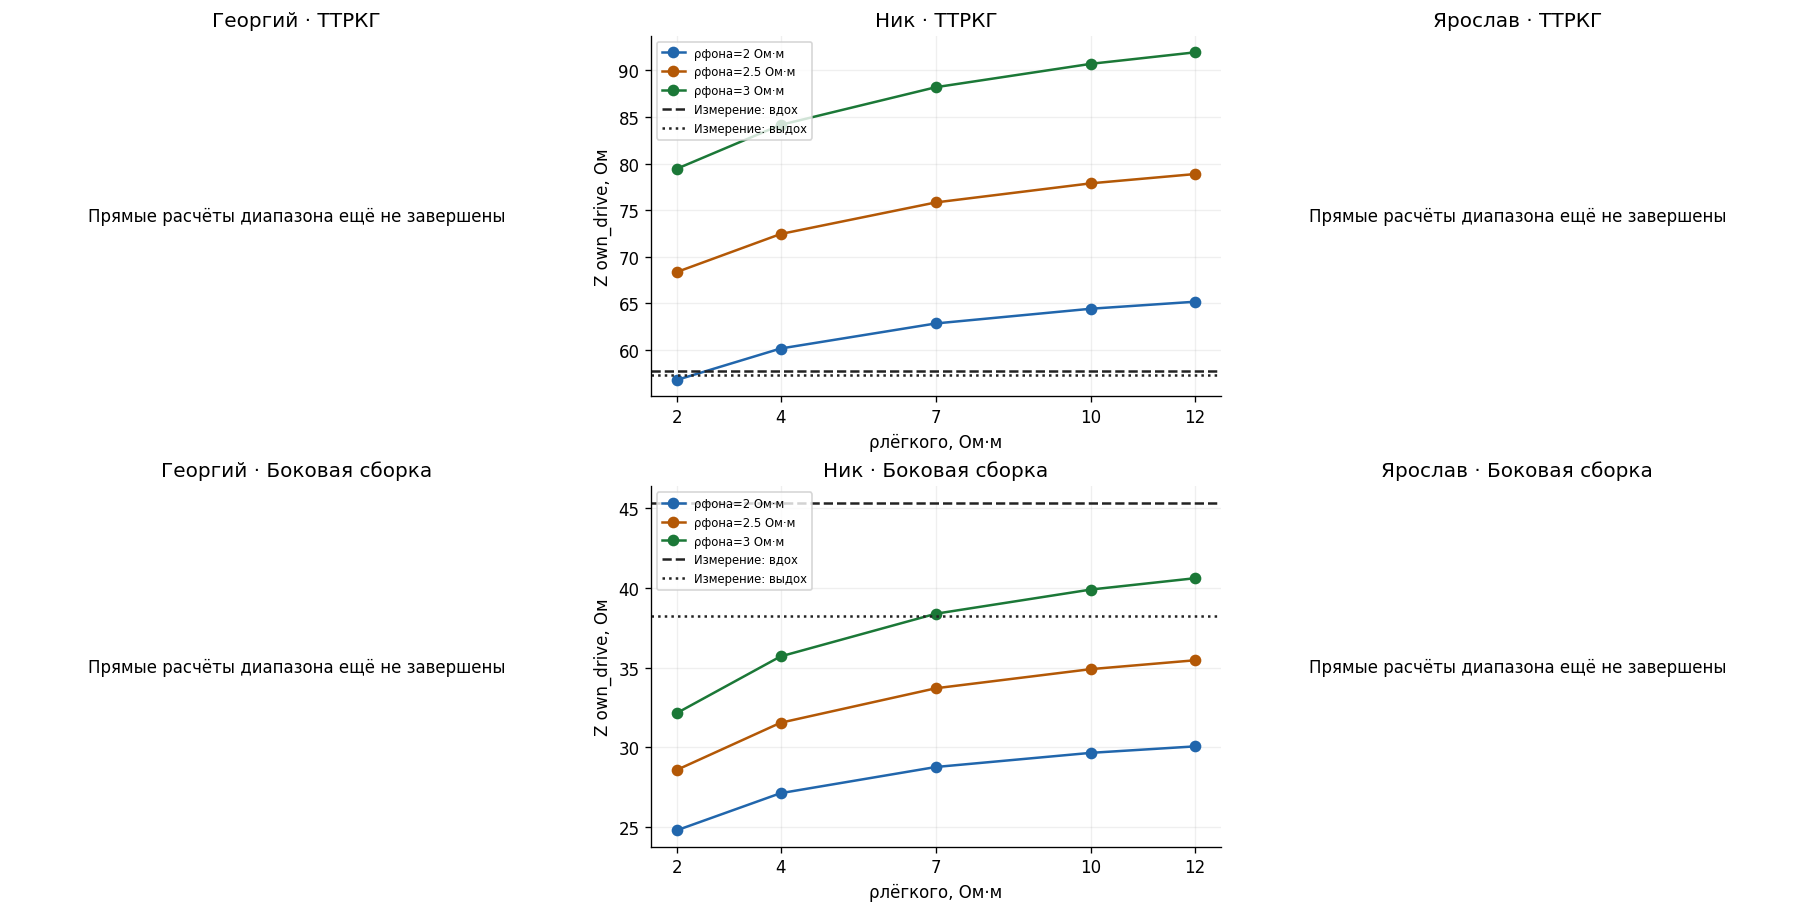

In [12]:
F.show_figure(F.fig_material_grid(S))

**Рисунок 6. Новая сетка сопротивлений для 140 мм/ТТРКГ 2×2, q4096, ρцелого сердца=1,35 Ом·м. По оси X — ρлёгкого, три цветные линии соединяют пять рассчитанных точек при ρфона 2; 2,5; 3 Ом·м. Горизонтальные линии — измеренные медианы вдоха и выдоха. Жир и кость фиксированы; own_drive является сценарием.**

На рассчитанных точках рисунка 6 диапазон own_drive составляет: Ник: ТТРКГ 56.8016–91.9175 Ом, Боковая сборка 24.7971–40.6119 Ом. Каждая отмеченная точка является сохранённым прямым расчётом. Соединяющие отрезки организуют точки; дополнительные значения между ними не рассчитывались. Сценарным точкам не назначается состояние вдоха или выдоха: оба измеренных уровня показаны как отдельные ориентиры. Совпадение уровня с точкой не устанавливает единственность сопротивлений, фазу источников или индивидуальную физиологическую оценку.

Отделим объёмный ответ при заданном свойстве крови от контрольного материального профиля рисунка 5 (рисунок 7).

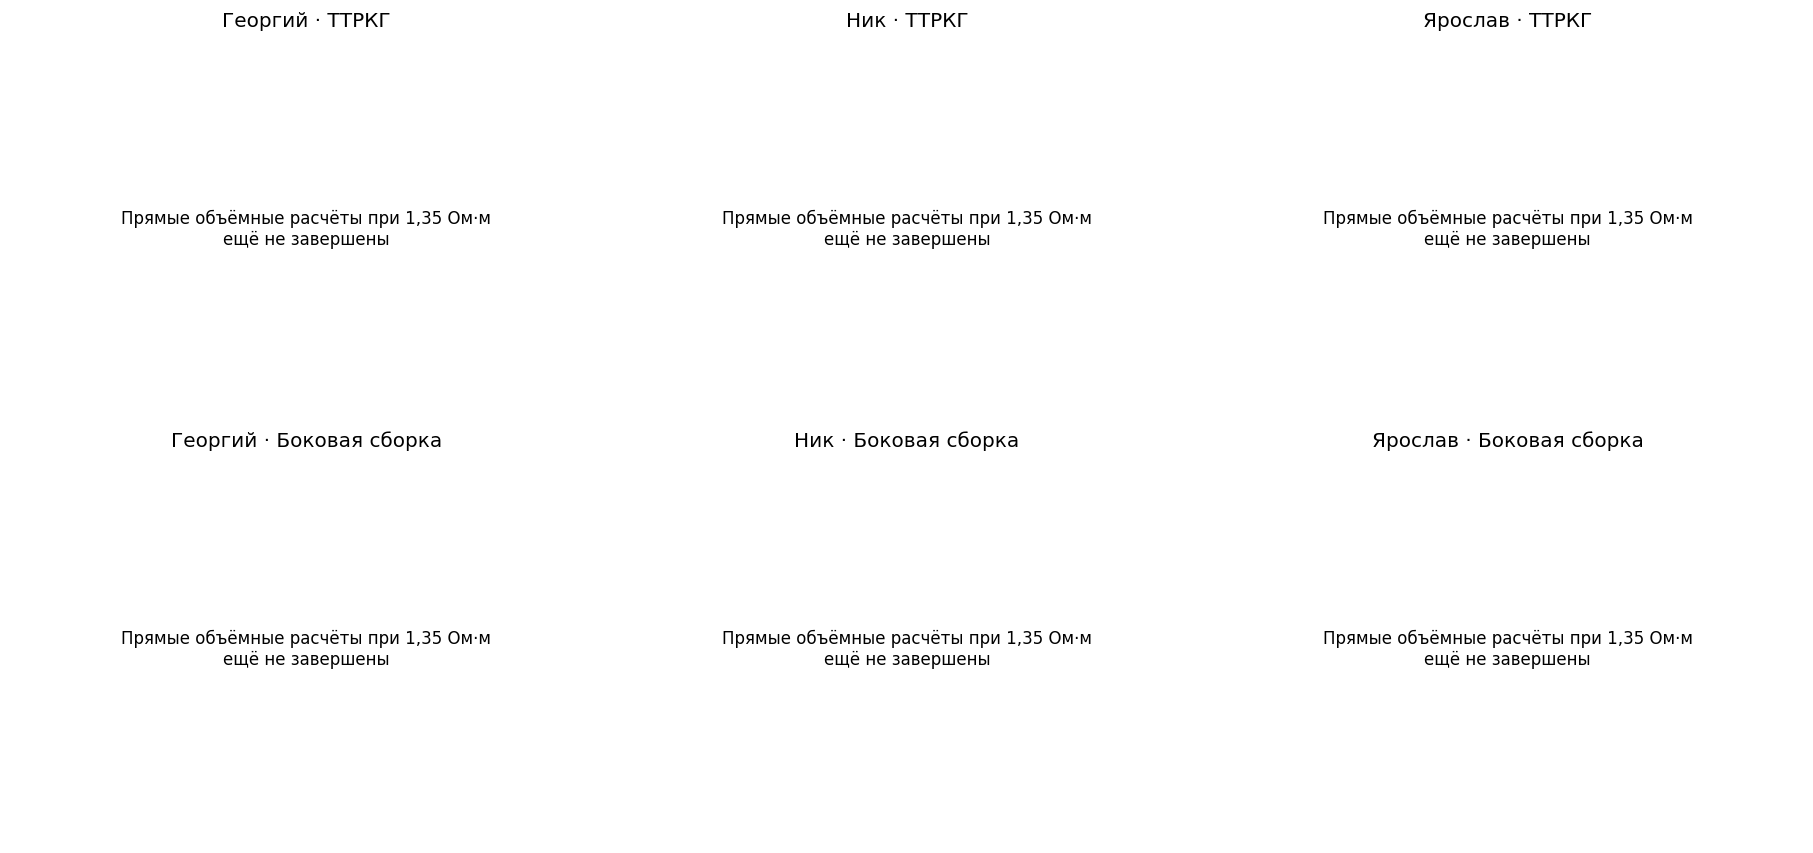

In [13]:
F.show_figure(F.fig_blood_sphere(S))

**Рисунок 7. Объёмные ответы own_drive при ρфона=2,5, ρлёгкого=7 и ρцелого сердца=1,35 Ом·м. Кружки — сферы с тремя объёмами, звёзды — исходная маска целого сердца при тех же свойствах. Серый — q1024, красный — q4096. На оси X — интегрированный объём, мл.**

Прямые объёмные расчёты при 1,35 Ом·м ещё не завершены; численных объёмных выводов по этой ветви пока нет. Для этой ветви используются собственные материальные блоки каждого объёмного варианта. Изменение сопротивления сердечной области относительно контрольного профиля не заменяет проверки её анатомического состава. Разность сферы и маски при одинаковом целевом объёме характеризует эффект формы в заданной модели; три точки не дают обоснования для расчёта ударного объёма или экстраполяции секущей за проверенный диапазон.

<a id="conclusion"></a>
## 8. Вывод и воспроизведение

**Модельный результат.** Индивидуальные прямые модели дают знаковые базовые
ответы, локальные производные и условный дыхательный контраст при явно заданных
материалах и источниках. Совместный набор монтажей улучшает обусловленность
по сравнению с каждым отведением отдельно; слабое направление, связанное с
сердцем, сохраняется. Количественная оценка четырёх тканевых сопротивлений
по реальным данным пока не установлена.

**Экспериментальное сопоставление.** Абсолютные уровни и парные разности
сопоставлены отдельно. Фаза источников, демодуляция, контакты, кандидатные
дыхательные интервалы и состояние между последовательными монтажами
ограничивают объяснение невязок. Шесть отказов размещения не дают электрической
оценки его погрешности. Сеточная сходимость и клиническая валидация не доказаны;
УО/ФВ в этом вычислительном цикле не получены.

Отчёт читает сохранённые JSON и обезличенный агрегат. При чистом запуске
ноутбука выполняются загрузка агрегата, арифметическая постобработка и построение
семи рисунков; FEM, КТ и сигналы не пересчитываются. Полные источники доступны
локально, а ниже сохранены только относительные пути и SHA. HTML экспортируется
без исходного Python-кода. Окончательная готовность входов не повышает
доказательный статус научных выводов.

**Совместность новой материальной сетки.** Ник: минимальная норма двух невязок на сетке 17.0103 Ом для вдоха и 10.9561 Ом для выдоха. Эти числа относятся к own_drive и 15 рассчитанным точкам; выбор иной неизвестной фазы и непрерывный подбор сопротивлений здесь не выполнялись. Снижение отдельной невязки нельзя принимать за согласие обоих отведений.

In [14]:
display(HTML(F.table_html(['Относительный источник','SHA-256'],[[r['relative_path'],r['sha256']] for r in S['sources']],'Таблица 7. Происхождение сохранённых агрегатов и прямых результатов')))

Относительный источник,SHA-256
georg/cem/cem_contacts_manifest.local.json,ab6f8f67528f97b54485bc6e7b1db1c7a67cb8d3d723d335a6a16865dea2b0bc
georg/cem_contacts_input/cem_contacts_input.local.json,a00da9355909e60a3733743e6dde9adebbb659707809fb0a36395b7ce986d562
georg/electrical/forward.local.json,1df145f06fd3e69f4da3e88cae044b4bb6a79e95ed4188b0ad405016650bc3e3
georg/heart_pilot/plan.local.json,2f0335f0978e805646e1ecd9e25ec1444ce3a328894fd1171d587ed12e672479
georg/materials/mesh_quality.local.json,98a1d89a015cae64776590e4335cfff16720c8c834251b0767c279e2658905cf
georg/placement_prepared/contact_plan.local.json,4d68540025d93e9686615473ba451ae3bd892ff0031739b08fcda8c1210e2d66
georg/reference_materials.local.json,8b970ce6600c9a55be200e1465a1eec2612c4834eca764c5f7070f19e931459a
georg/sensitivity/sensitivity.local.json,34a48785bda0a75cdda491fa41787ea59ec0d9b2993849cc4dbf32265589659c
nik/cem/cem_contacts_manifest.local.json,fbac8c67e0e9c2c01b727bd4378329868ea8a123fd86511aa99ea4a0e06188fa
nik/cem_contacts_input/cem_contacts_input.local.json,804e4417b5b9b1f284a162f2051b707d57a643cc007c9fa84695da8a7ca47b8a
